# 07 — Interpretability with SHAP

Which features push a prediction towards fighter A or fighter B, and by how much?
SHAP splits each fight's prediction into one piece per feature:

    score = 0 + piece from Elo + piece from age + ...   (40 pieces)

Each piece is that feature's **SHAP value** for that fight. Positive pushes towards
fighter A, negative towards fighter B. Units are **log-odds**: near 50%, +0.1 is about
+2.5 percentage points, +0.4 about +10.

Two adjustments, so the explanation matches what the model really predicts
(`modeling/explain.py`):

- **Both corners.** Every fight is predicted both ways round, so SHAP is computed
  both ways round and combined. The baseline is then exactly 0: a fight with no
  information is 50-50.
- **All 8 seeds.** The final predictor is 8 models; their SHAP values are averaged.

**Which fights.** SHAP never looks at who won, only at what the model predicted, so
looking at the validation years spends nothing. The main view is **validation
(2023–24)**: fights the model never trained on. The **training years (2014–22)** are
the cross-check: if both tell the same story, the patterns are stable. The test years
stay closed.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from scipy.special import expit

from ufc_predictor.data.io import load_processed
from ufc_predictor.features import manifest
from ufc_predictor.modeling.explain import group_shap, shap_values, symmetric_score
from ufc_predictor.modeling.model import fit_models, predict_proba_mean
from ufc_predictor.modeling.split import chronological_split
from ufc_predictor.modeling.tune import load_params

featured = load_processed("fights_featured")
train, validation, _ = chronological_split(featured)      # the test years stay closed
X_train, y_train = manifest.make_xy(train)
X_val, _ = manifest.make_xy(validation)

# the final predictor: tuned settings, 8 seeds
models = fit_models(X_train, y_train, load_params())

val = shap_values(models, X_val)
trn = shap_values(models, X_train)
print(f"validation: {val.values.shape[0]:,} fights x {val.values.shape[1]} features | training: {trn.values.shape[0]:,} fights")

validation: 1,017 fights x 40 features | training: 4,309 fights


In [2]:
# checks: the pieces add up to the explained score, and that score tells the same
# story as the real prediction
S = symmetric_score(models, X_val)
p = predict_proba_mean(models, X_val)
assert np.allclose(val.values.sum(axis=1), S)
gap = np.abs(expit(S) - p)
print(f"pieces add up exactly; explained score vs real prediction: largest gap {gap.max():.2%}, "
      f"same pick in {((S > 0) == (p > 0.5)).mean():.0%} of fights")

# shorter names for the plots: drop the diff_prior_ / diff_static_ prefix
def short(column):
    for prefix in ("diff_prior_", "diff_static_", "diff_"):
        if column.startswith(prefix):
            return column[len(prefix):]
    return column

for e in (val, trn):
    e.feature_names = [short(c) for c in e.feature_names]
assert len(set(val.feature_names)) == len(val.feature_names)

pieces add up exactly; explained score vs real prediction: largest gap 1.92%, same pick in 100% of fights


## 1. Which families matter

Features that measure similar things split the credit between them: 32 striking
features each look small even if striking as a whole matters. So first, the SHAP
values are added up within each feature group from `manifest.py` (exact: the groups
still add up to the score). The bar is the average size of a group's push,
ignoring direction.

In [3]:
groups = manifest.feature_groups(train)
val_groups = group_shap(shap_values(models, X_val), groups)
trn_groups = group_shap(shap_values(models, X_train), groups)

table = pd.DataFrame({
    "columns": [len(groups[g]) for g in val_groups.feature_names],
    "validation": np.abs(val_groups.values).mean(axis=0),
    "training": np.abs(trn_groups.values).mean(axis=0),
}, index=val_groups.feature_names).sort_values("validation", ascending=False)
table["per_column"] = table["validation"] / table["columns"]
table.round(4)

,columns,validation,training,per_column
strength,1,0.2447,0.2417,0.2447
physical,5,0.2133,0.2200,0.0427
defence,11,0.1685,0.1671,0.0153
striking,13,0.1094,0.0985,0.0084
grappling,4,0.0855,0.0738,0.0214
cold_start,2,0.0238,0.0252,0.0119
record,3,0.0186,0.0177,0.0062
damage,1,0.0075,0.0072,0.0075
pace,0,0.0000,0.0000,NaN


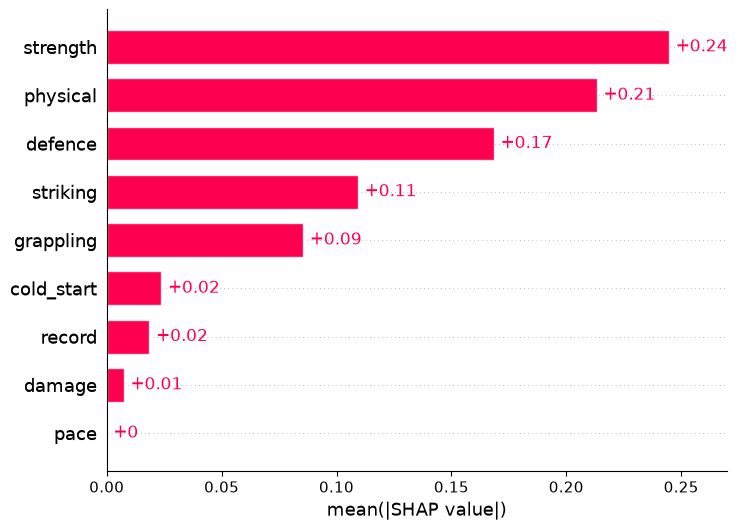

In [4]:
shap.plots.bar(val_groups, max_display=len(groups))

Two families carry the model: **strength**, the single Elo column (now weighting each win by how it
came), and **physical** (age gap, reach, height, weight class). The Elo column alone outweighs all 11
defence inputs together. Training and validation agree to within 0.015 for every group, and the top
five come in the same order as the permutation importance in `05_elo.ipynb` (the bottom three are
all close to zero there). Two different methods telling the same story is what makes it believable.

## 2. Beeswarm: validation years

One row per feature, the 15 that move predictions most. Each dot is one fight: how
far right or left it sits is how much that feature pushed the prediction; its colour
is the feature's value (red high, blue low). Every feature is fighter A minus fighter
B, so *red* means "A has more of it than B".

How to read a row: if red dots sit on the right, having more of this feature than
your opponent makes the model favour you.

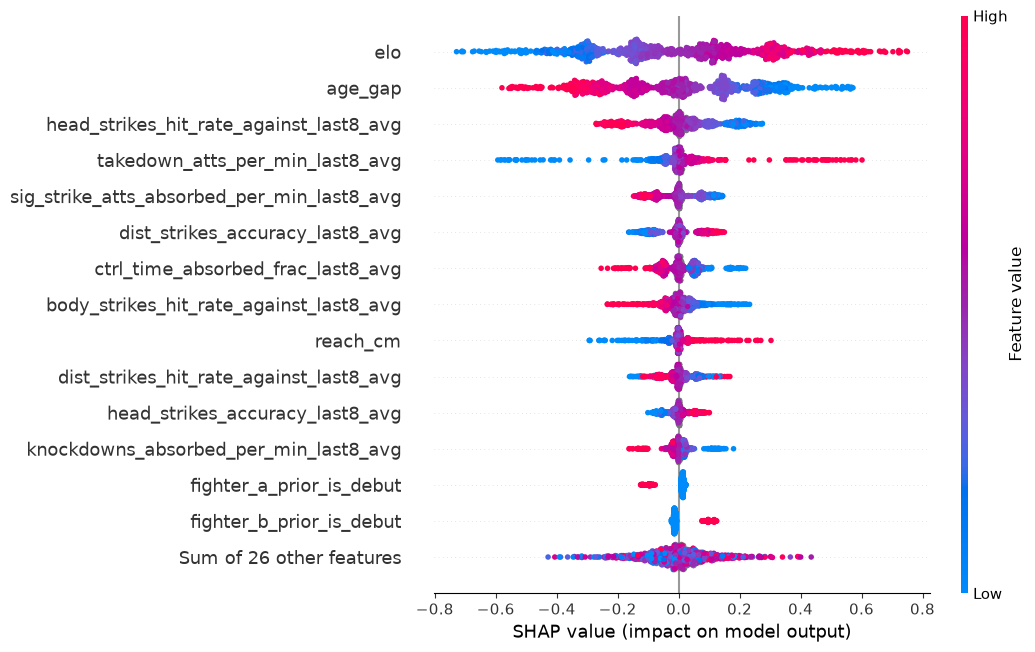

In [5]:
shap.plots.beeswarm(val, max_display=15)

## 3. Beeswarm: training years, the cross-check

The same plot on the 4,309 fights the model learned from. If the order and the
colour pattern match the validation plot, the model behaves the same way on fights it
has seen and fights it hasn't.

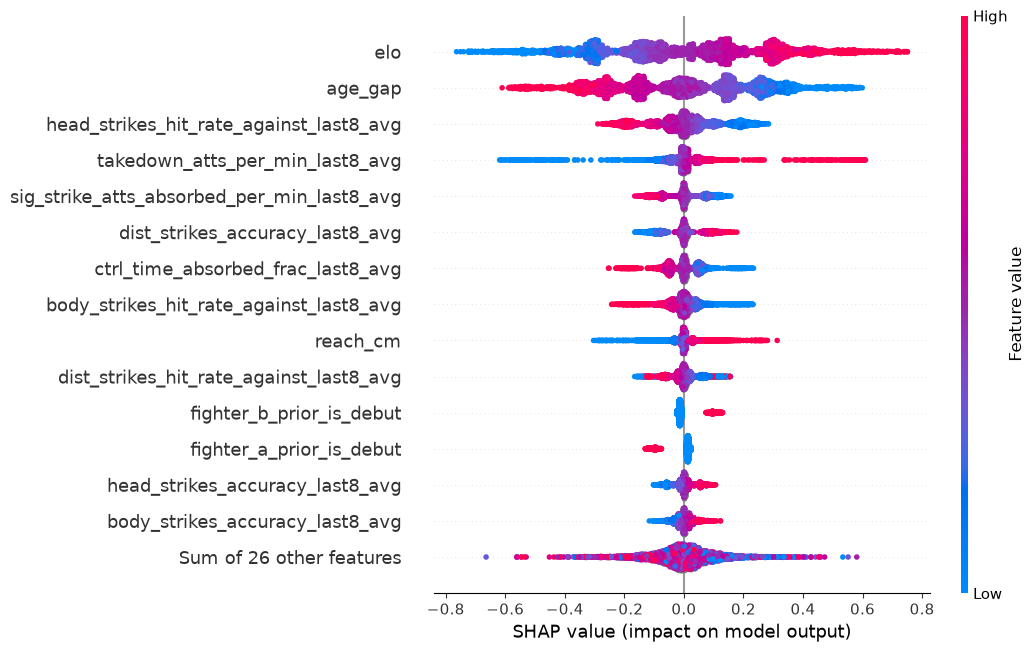

In [6]:
shap.plots.beeswarm(trn, max_display=15)

In [7]:
# the same comparison as numbers: the top 15 on validation, and where each ranks in training
def ranking(e):
    importance = pd.Series(np.abs(e.values).mean(axis=0), index=e.feature_names)
    return importance.sort_values(ascending=False)

v, t = ranking(val), ranking(trn)
top = pd.DataFrame({
    "validation_rank": range(1, 16),
    "mean_abs_shap": v.head(15).round(4).to_numpy(),
    "training_rank": [t.index.get_loc(f) + 1 for f in v.head(15).index],
}, index=v.head(15).index)
top

,validation_rank,mean_abs_shap,training_rank
elo,1,0.2447,1
age_gap,2,0.2053,2
head_strikes_hit_rate_against_last8_avg,3,0.0856,3
takedown_atts_per_min_last8_avg,4,0.0609,4
sig_strike_atts_absorbed_per_min_last8_avg,5,0.0576,5
dist_strikes_accuracy_last8_avg,6,0.0523,6
ctrl_time_absorbed_frac_last8_avg,7,0.0477,7
body_strikes_hit_rate_against_last8_avg,8,0.0410,8
reach_cm,9,0.0311,9
dist_strikes_hit_rate_against_last8_avg,10,0.0311,10


## 4. Dependence plots: the shape of each effect

One plot per feature, for the four that matter most. The x-axis is the feature's
value (A minus B), the y-axis its SHAP value: how far it moved the prediction for
that fight, measured from 50-50. A straight line means "every extra unit counts the
same"; a curve that flattens means "differences beyond a point stop mattering".

The colour is a second feature, the one SHAP finds interacts most with this one. If
the red and blue dots separate vertically, the effect of the x-axis feature depends
on the colour feature.

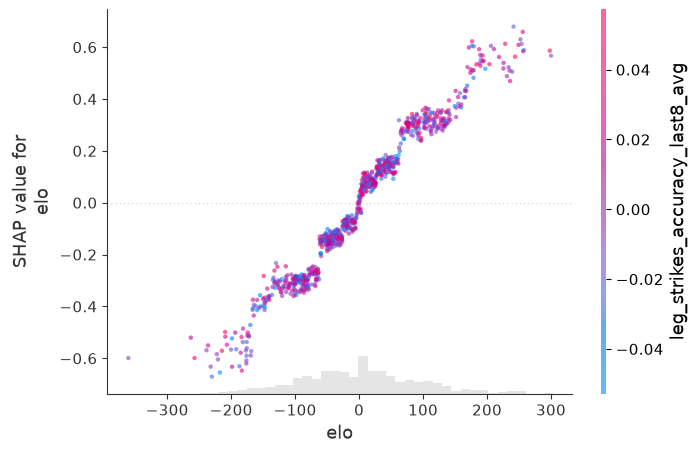

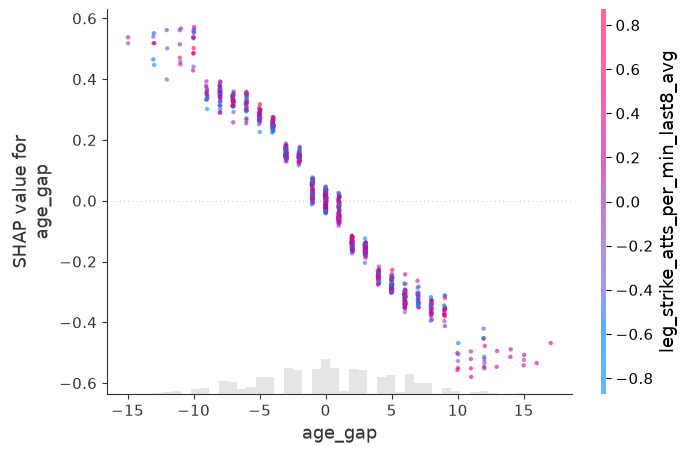

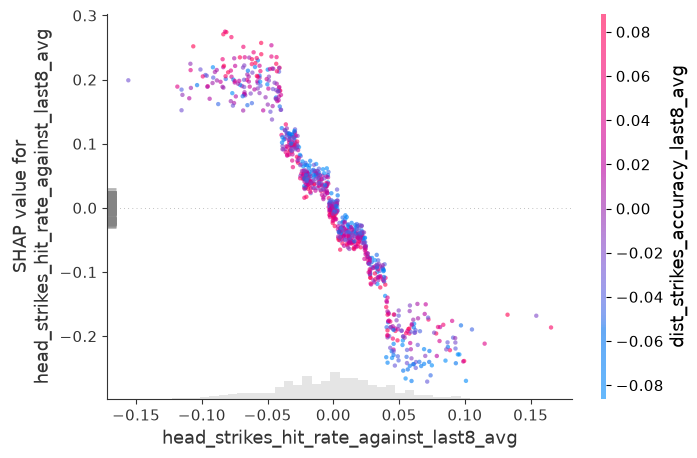

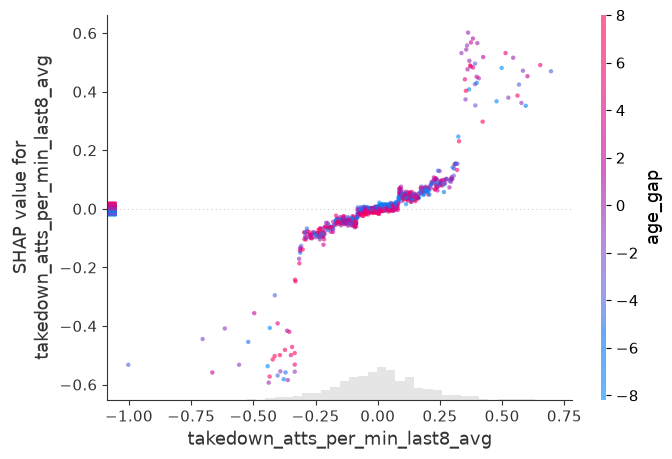

In [8]:
for feature in v.index[:4]:
    shap.plots.scatter(val[:, feature], color=val, alpha=0.6, dot_size=10)

## What it shows

1. **Two features do most of the work.** Elo (0.245) and age gap (0.205) each move predictions
   more than twice as much as the next feature, how often the fighter gets hit in the head (0.086).
2. **Every direction makes sense.** Higher Elo, younger than your opponent, harder to hit, more
   takedown and submission attempts, more accurate: the model favours you. Facing more strikes,
   spending more time controlled, suffering more knockdowns: it favours your opponent.
3. **Age gap is close to a straight line.** About 0.045 log-odds per year, roughly one percentage
   point, flattening beyond about 10 years. A 10-year gap is worth about 11 points.
4. **Elo is close to a straight line too, and steeper than the classic rating.** About 0.25
   log-odds per 100 rating points (6 percentage points), up to about ±0.6 (±15 points). The weighted
   ratings sit closer together, so each point means more.
5. **The fight stats are ramps that level off**: beyond a few points of difference, more adds
   nothing. The grey strip on the left of those plots is fights where the feature is missing (a
   debutant): no push either way.
6. **No strong interactions.** In the dependence plots the colours don't separate vertically.
7. **The story is stable.** Training and validation rank the same top features, within a few places.